# Pal et al. 2021 — Breast Cancer (10x)
## 04 · EMT-TF expression (unconditional)

Overlay of thresholded EMT-transcription-factor expressers on the grey manifold. TFs are gated on
detectable expression and drawn from a wide panel (Snail/Zeb/Twist **plus** the FOXC and PRRX mesenchymal
families); VIM is a mesenchymal marker, not a TF, and is excluded. The most informative pair (root-end vs
terminus-end along pseudotime) is derived from the data. Categorical overlay with display cutoffs — not a
continuous single-gene colormap.

In [1]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*6))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_fig, exist_ok=True)

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'signatures.h5ad'))
adata.obsm['X_umap'] = adata.obsm['X_umap_lin']   # house linear layout
# EMT-TF readout scored on the developmental Body (defined pseudotime)
body = adata[adata.obs['t'].notna()].copy()
t = body.obs['t'].values; tn=(t-t.min())/(t.max()-t.min())
print('Body cells:', body.shape[0], '| pseudotime', round(t.min(),2), '->', round(t.max(),2))

Body cells: 45191 | pseudotime 0.0 -> 8.69


### Derive the informative EMT-TFs
Classify each detected TF by its own pseudotime trend (rho sign: root vs terminus). Report a
root↔terminus pair when both poles are populated; if no EMT-TF is terminus-enriched, report that
the EMT-TF field concentrates at the origin and show the strongest and most-expressed root factors.

In [4]:
panel = ['SNAI1','SNAI2','ZEB1','ZEB2','TWIST1','TWIST2','FOXC1','FOXC2','PRRX1','PRRX2']
present = [g for g in panel if g in adata.var_names]
early = tn <= np.quantile(tn,1/3); late = tn >= np.quantile(tn,2/3)
X = body[:,present].X; X = X.toarray() if hasattr(X,'toarray') else np.asarray(X)
rows=[]
for j,g in enumerate(present):
    x=X[:,j]; rho,p=spearmanr(tn,x)
    rows.append((g, round((x>0).mean(),3), round(x[early].mean(),3), round(x[late].mean(),3), round(rho,3)))
df = pd.DataFrame(rows, columns=['TF','frac_expr','mean_early','mean_late','rho_vs_t'])
df['end'] = np.where(df.rho_vs_t < 0,'root','terminus')   # single criterion: pseudotime trend sign
df = df.sort_values('rho_vs_t'); print(df.to_string(index=False))
FLOOR = 0.03
ok = df[df.frac_expr > FLOOR]
root_tfs = ok[ok.rho_vs_t < 0].sort_values('rho_vs_t')     # most negative rho = strongest root
term_tfs = ok[ok.rho_vs_t > 0].sort_values('rho_vs_t')     # positive rho = terminus-enriched
if len(term_tfs) > 0:
    tf_a = root_tfs.iloc[0]['TF']; tf_b = term_tfs.iloc[-1]['TF']
    label_a, label_b = f'{tf_a} (root)', f'{tf_b} (terminus)'
    print(f'\nderived pair: {tf_a} (root/origin) <-> {tf_b} (terminus)')
else:
    # no EMT-TF is terminus-enriched: the whole EMT-TF field concentrates at the pSom/origin pole
    tf_a = root_tfs.iloc[0]['TF']                            # strongest root by rho
    tf_b = ok.sort_values('frac_expr').iloc[-1]['TF']        # most broadly expressed (also root here)
    label_a, label_b = f'{tf_a} (strongest root)', f'{tf_b} (most expressed)'
    print(f'\nno terminus-enriched EMT-TF detected (all detected TFs trend to the pSom/origin pole).')
    print(f'derived pair: {tf_a} (strongest root, rho={ok.set_index("TF").loc[tf_a,"rho_vs_t"]:+.3f}) '
          f'and {tf_b} (most expressed, {ok.set_index("TF").loc[tf_b,"frac_expr"]*100:.0f}%); both root/origin-enriched.')
    print(f'note: only terminus-trending factor is TWIST1 (rho +0.047) but it is below the {FLOOR} detection floor.')

    TF  frac_expr  mean_early  mean_late  rho_vs_t      end
 PRRX2      0.062       0.078      0.007    -0.232     root
 FOXC2      0.034       0.057      0.002    -0.229     root
 SNAI2      0.063       0.068      0.012    -0.163     root
 PRRX1      0.020       0.028      0.002    -0.145     root
 FOXC1      0.142       0.097      0.051    -0.097     root
 SNAI1      0.044       0.012      0.007    -0.030     root
  ZEB2      0.012       0.004      0.002    -0.019     root
  ZEB1      0.006       0.003      0.001    -0.016     root
TWIST2      0.003       0.001      0.001    -0.014     root
TWIST1      0.024       0.004      0.007     0.047 terminus

no terminus-enriched EMT-TF detected (all detected TFs trend to the pSom/origin pole).
derived pair: PRRX2 (strongest root, rho=-0.232) and FOXC1 (most expressed, 14%); both root/origin-enriched.
note: only terminus-trending factor is TWIST1 (rho +0.047) but it is below the 0.03 detection floor.


### Figure — EMT-TF expression overlay
Expressers above the upper-quartile-among-expressers cutoff are overlaid categorically on the grey
manifold (root-end TF blue, terminus-end TF red).

overlay thresholds (upper quartile among expressers): {'PRRX2': 0.659, 'FOXC1': 0.587} | cells shown: {'PRRX2': 1358, 'FOXC1': 2435}
PRRX2: 9.2% expressing; 1358 shown
FOXC1: 16.4% expressing; 2435 shown
saved expression.pdf


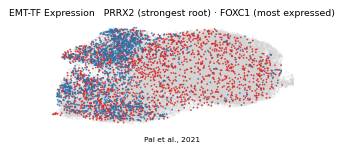

In [5]:
def _vec(g):
    x = adata[:,g].X; return x.toarray().ravel() if hasattr(x,'toarray') else np.asarray(x).ravel()
thr={}
for g in [tf_a,tf_b]:
    v=_vec(g); pos=v[v>0]; thr[g]=float(np.quantile(pos,0.75)) if pos.size else 0.0
sel={g:_vec(g)>thr[g] for g in [tf_a,tf_b]}
print('overlay thresholds (upper quartile among expressers):', {g:round(thr[g],3) for g in [tf_a,tf_b]},
      '| cells shown:', {g:int(sel[g].sum()) for g in [tf_a,tf_b]})
xl = adata.obsm['X_umap']
xlo,xhi=np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi=np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
order=sorted([tf_a,tf_b], key=lambda g:-int(sel[g].sum()))
colors={tf_a:'tab:blue', tf_b:'tab:red'}
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(adata, size=8, alpha=.3, frameon=False, show=False, ax=ax, na_color='lightgray')
for g in order:
    ap=adata[sel[g]].copy()
    sc.pl.umap(ap, na_color=colors[g], size=8, alpha=.85, frameon=False, show=False, ax=ax)
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.set_title(f'EMT-TF Expression   {label_a} · {label_b}', size=7.5)
ax.text(.5,-.14,'Pal et al., 2021', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'expression.pdf'), bbox_inches='tight')
for g in [tf_a,tf_b]:
    print(f'{g}: {(_vec(g)>0).mean()*100:.1f}% expressing; {int(sel[g].sum())} shown')
print('saved expression.pdf')